# Imports

In [1]:
# Import all libraries needed for EDA, preprocessing, modeling and evaluation
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
from xgboost import XGBClassifier
import joblib, warnings
warnings.filterwarnings('ignore')

# Load Dataset

In [2]:
# Load the dataset from CSV into a DataFrame for analysis
df = pd.read_csv('Dataset/diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Basic Info

In [3]:
# Check data types, nulls and shape to plan preprocessing
df.info()
print(df.describe())
print("Shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.

# Target Distribution

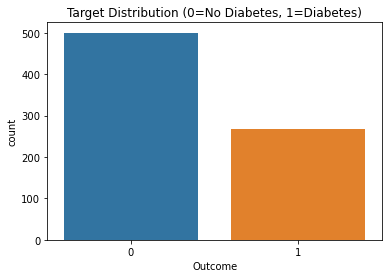

0    0.651042
1    0.348958
Name: Outcome, dtype: float64


In [4]:
# Check class balance to decide if SMOTE / class_weight is needed
sns.countplot(x='Outcome', data=df)
plt.title('Target Distribution (0=No Diabetes, 1=Diabetes)')
plt.show()
print(df['Outcome'].value_counts(normalize=True))

# Handle Invalid Zeros

In [5]:
# In this dataset, 0 in medical features means missing -> replace with NaN
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


# Impute Missing Values 

In [6]:
# Fill NaNs with median (robust to outliers) instead of dropping rows
imputer = SimpleImputer(strategy='median')
df[zero_cols] = imputer.fit_transform(df[zero_cols])
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

# EDA: Correlation Heatmap

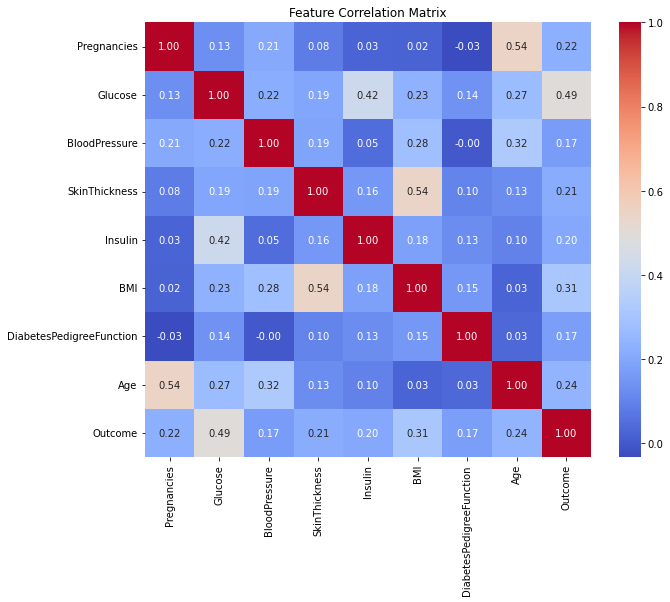

In [7]:
# Visualize feature correlation to spot multicollinearity
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

# EDA: Distribution Plots

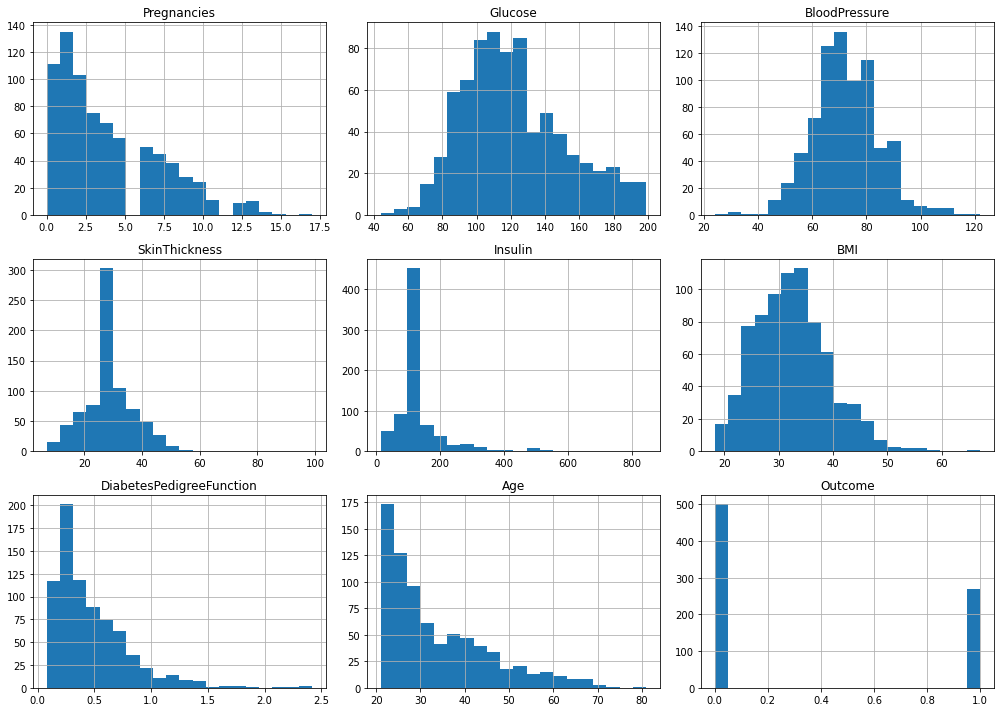

In [8]:
# Understand feature distributions & outliers before scaling
df.hist(figsize=(14,10), bins=20)
plt.tight_layout(); plt.show()

# Split Features/Target

In [9]:
# Separate independent (X) and dependent (y) variables
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Train/Test Split

In [10]:
# Split data — stratify keeps class ratio same in train & test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling

In [11]:
# StandardScaler helps distance-based models (LogReg, SVM, KNN) converge faster
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Define Multiple Models

In [12]:
# Compare multiple algorithms to pick the best performer
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Train & Evaluate All Models

In [13]:
# Train every model and record accuracy, precision, recall, F1, ROC-AUC
results = []
for name, model in models.items():
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)
    y_prob = model.predict_proba(X_test_sc)[:,1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,XGBoost,0.766234,0.680000,0.629630,0.653846,0.820370
3,Gradient Boosting,0.759740,0.688889,0.574074,0.626263,0.830741
6,KNN,0.753247,0.660000,0.611111,0.634615,0.788611
2,Random Forest,0.740260,0.652174,0.555556,0.600000,0.816111
5,SVM,0.740260,0.652174,0.555556,0.600000,0.796389
0,Logistic Regression,0.707792,0.600000,0.500000,0.545455,0.812963
1,Decision Tree,0.681818,0.553191,0.481481,0.514851,0.635741


# Visualization Comparison

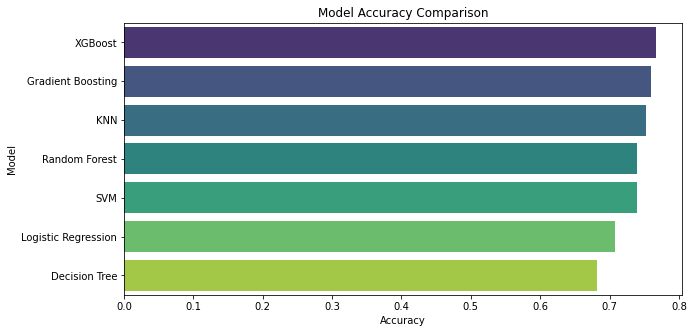

In [14]:
# Bar chart of accuracy for easy comparison
plt.figure(figsize=(10,5))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette='viridis')
plt.title('Model Accuracy Comparison')
plt.show()

# Confusion Matrices

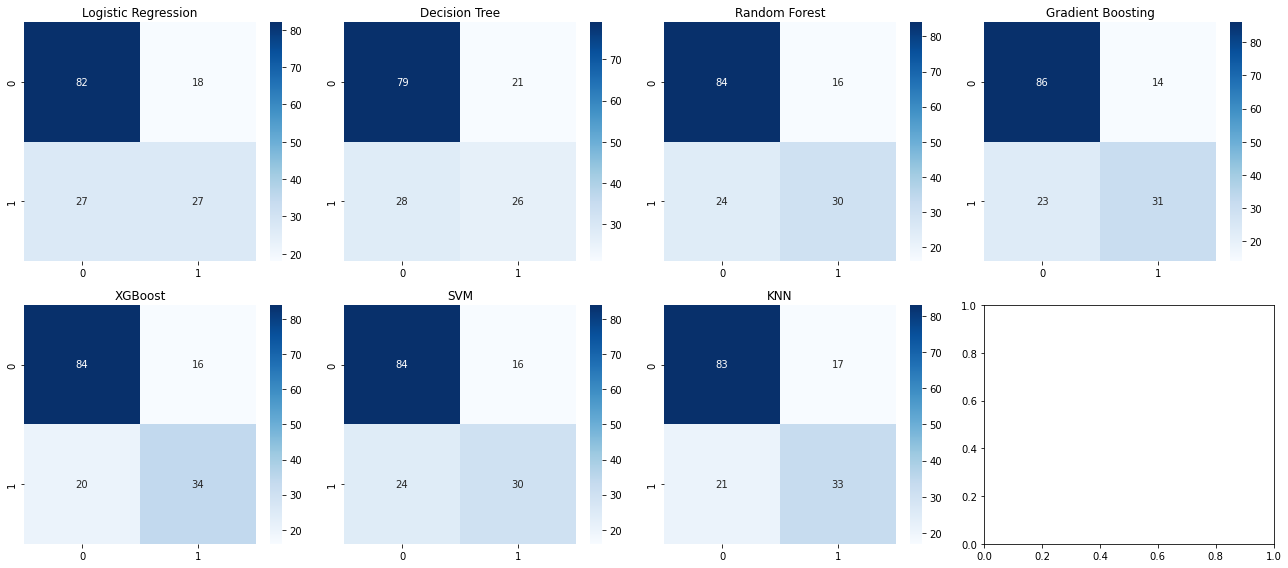

In [15]:
# Confusion matrices reveal false positives vs false negatives trade-off
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_sc))
    sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.show()

# Hyperparameter Tuning (Best Model = XGBoost)

In [16]:
# Tune XGBoost (usually highest accuracy) to squeeze more performance
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

grid = GridSearchCV(XGBClassifier(eval_metric='logloss', random_state=42),
                    param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_sc, y_train)

print("Best Params:", grid.best_params_)
print("Best CV Score:", grid.best_score_)
best_model = grid.best_estimator_

Best Params: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Best CV Score: 0.7720111955217912


# Final Evaluation

In [17]:
# Evaluate tuned model on the untouched test set
y_pred = best_model.predict(X_test_sc)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test Accuracy: 0.7337662337662337
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       100
           1       0.64      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.70       154
weighted avg       0.73      0.73      0.73       154



# ROC Curve

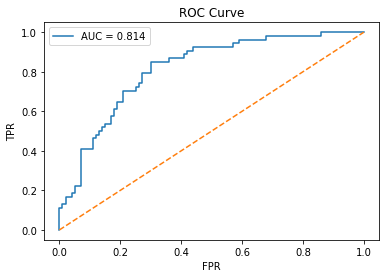

In [18]:
# ROC curve visualizes model's ability to separate classes
y_prob = best_model.predict_proba(X_test_sc)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')
plt.plot([0,1],[0,1],'--')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.title('ROC Curve')
plt.show()

# Save Model & Scaler

In [19]:
# Persist model + scaler so app.py can load them without retraining
joblib.dump(best_model, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Saved model.pkl and scaler.pkl")

Saved model.pkl and scaler.pkl
